# 02 · LeNet, VGG y Batch Normalization

Entrenaremos cuatro modelos: LeNet, LeNet+BN, VGG-11 y VGG-11+BN.
Luego probaremos una tasa de aprendizaje más alta. Esto cubre las tareas 1 y 2.

## Preparación

Sube la carpeta `PC3_Deep_Learning` a **Mi unidad** de Google Drive, incluyendo
`data/raw/` con las imágenes descargadas. No hace falta subir `.venv`.
Usaremos esa carpeta en los tres notebooks. Ejecútalos en orden: **01 → 02 → 03**.
Para los notebooks 02 y 03, activa una GPU en Colab.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

%cd /content/drive/MyDrive/PC3_Deep_Learning

Mounted at /content/drive
/content/drive/MyDrive/PC3_Deep_Learning


In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as MostrarImagen
from src.utils import seed_everything

seed_everything(42)

## Modelos y parámetros

LeNet tiene dos bloques de convolución y pooling, y tres capas finales.
VGG-11 usa ocho convoluciones, cinco poolings y tres capas finales.
Sus filtros se reducen a la mitad y su parte final es más pequeña para ahorrar memoria.
Ambos reciben imágenes de 64×64. Las versiones con BN la aplican después de cada convolución.

Los pares con y sin BN usan los mismos datos, pesos iniciales compartidos,
semilla y ajustes. Los ajustes están en `src/train.py`.

In [6]:
from src.models import build_model, parameter_counts
from src.train import DEFAULT_SETTINGS, experiment_plan, run_suite
from src.utils import export_results

parametros = []
for modelo in experiment_plan(DEFAULT_SETTINGS, "scratch"):
    seed_everything(42)
    red = build_model(modelo["architecture"], modelo["batch_norm"])
    parametros.append({"modelo": modelo["name"], **parameter_counts(red)})
display(pd.DataFrame(parametros))
display(DEFAULT_SETTINGS)

,modelo,parameters,trainable_parameters
0,lenet_scratch_seed42,337976,337976
1,lenet_bn_scratch_seed42,338020,338020
2,vgg11_scratch_seed42,2963396,2963396
3,vgg11_bn_scratch_seed42,2966148,2966148


{'seed': 42,
 'validation_fraction': 0.2,
 'batch_size': 64,
 'num_workers': 2,
 'scratch_epochs': 10,
 'transfer_epochs': 5,
 'scratch_lr': 0.01,
 'high_lr': 0.1,
 'momentum': 0.9,
 'weight_decay': 0.0001,
 'transfer_lrs': {'feature': 0.001, 'partial': 0.0001, 'full': 1e-05},
 'scratch_size': 64,
 'transfer_size': 224,
 'augmentation': True}

## Entrenar los cuatro modelos

Ejecuta primero el notebook 01 para preparar las particiones.
Usaremos GPU, 10 épocas, batch 64 y SGD con LR 0.01.
Se guarda la mejor época según validación y después se evalúa en test.

In [7]:
resultados = run_suite(DEFAULT_SETTINGS, "scratch", device="cuda")
display(resultados[["name", "parameters", "mean_train_seconds", "test_accuracy", "epoch_to_80_val"]])

lenet_scratch_seed42:   0%|          | 0/10 [00:00<?, ?it/s]

lenet_scratch_seed42: completed; mejor val=0.6686746987951807; test=0.4672295938882187


lenet_bn_scratch_seed42:   0%|          | 0/10 [00:00<?, ?it/s]

lenet_bn_scratch_seed42: completed; mejor val=0.5873493975903614; test=0.3988741455568959


vgg11_scratch_seed42:   0%|          | 0/10 [00:00<?, ?it/s]

vgg11_scratch_seed42: completed; mejor val=0.25100401606425704; test=0.25090470446320867


vgg11_bn_scratch_seed42:   0%|          | 0/10 [00:00<?, ?it/s]

vgg11_bn_scratch_seed42: completed; mejor val=0.9764056224899599; test=0.8114193807800563


,name,parameters,mean_train_seconds,test_accuracy,epoch_to_80_val
0,lenet_scratch_seed42,337976,79.664632,0.467230,NaN
1,lenet_bn_scratch_seed42,338020,21.684756,0.398874,NaN
2,vgg11_scratch_seed42,2963396,23.727318,0.250905,NaN
3,vgg11_bn_scratch_seed42,2966148,23.831580,0.811419,5.0


## Curvas de pérdida y accuracy

Comparamos el progreso en entrenamiento y validación.

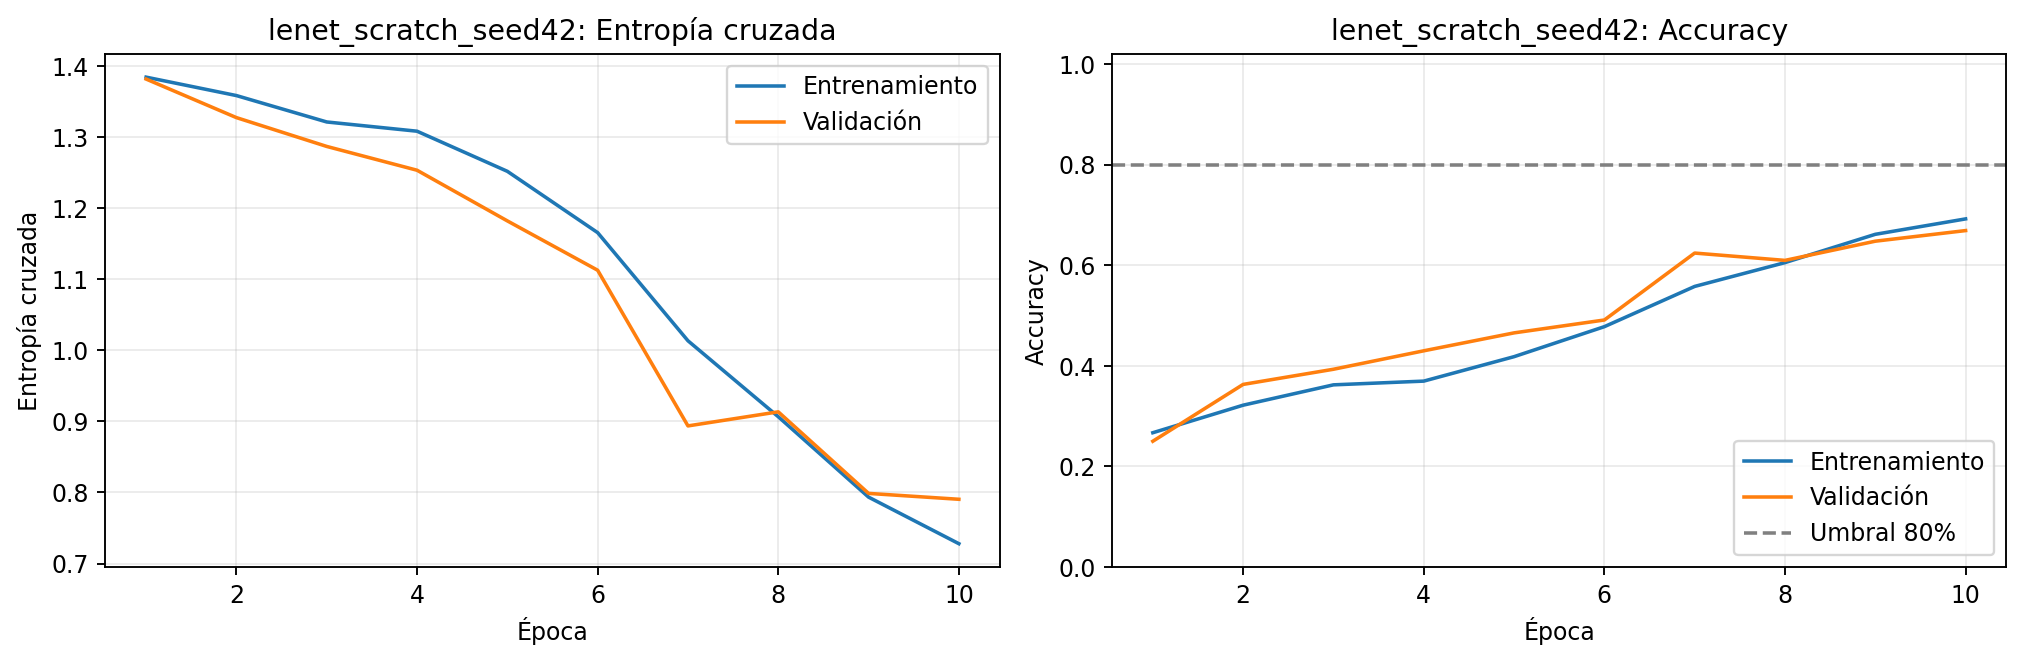

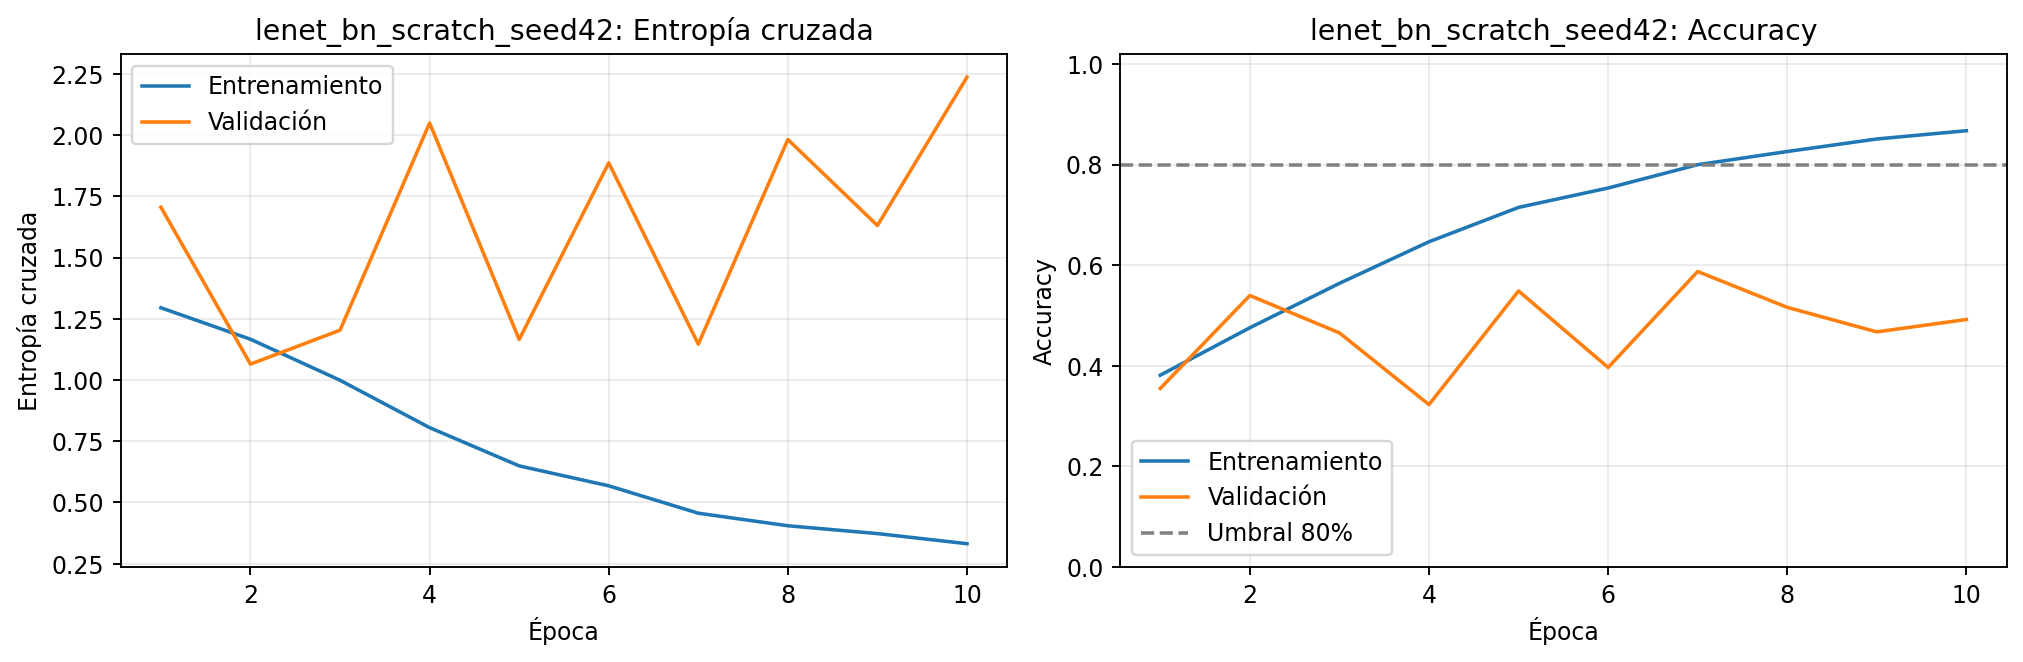

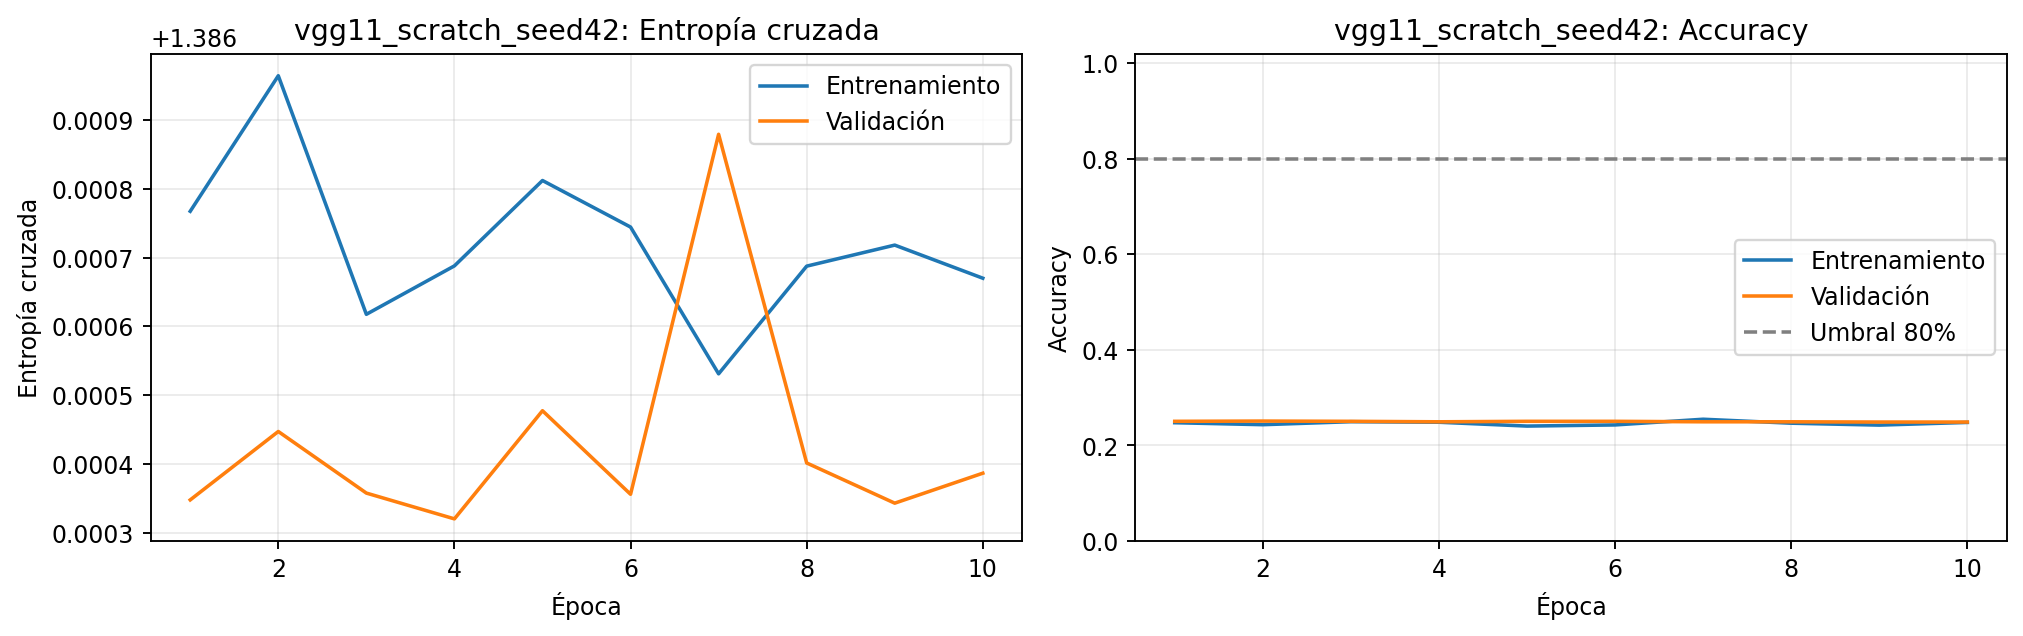

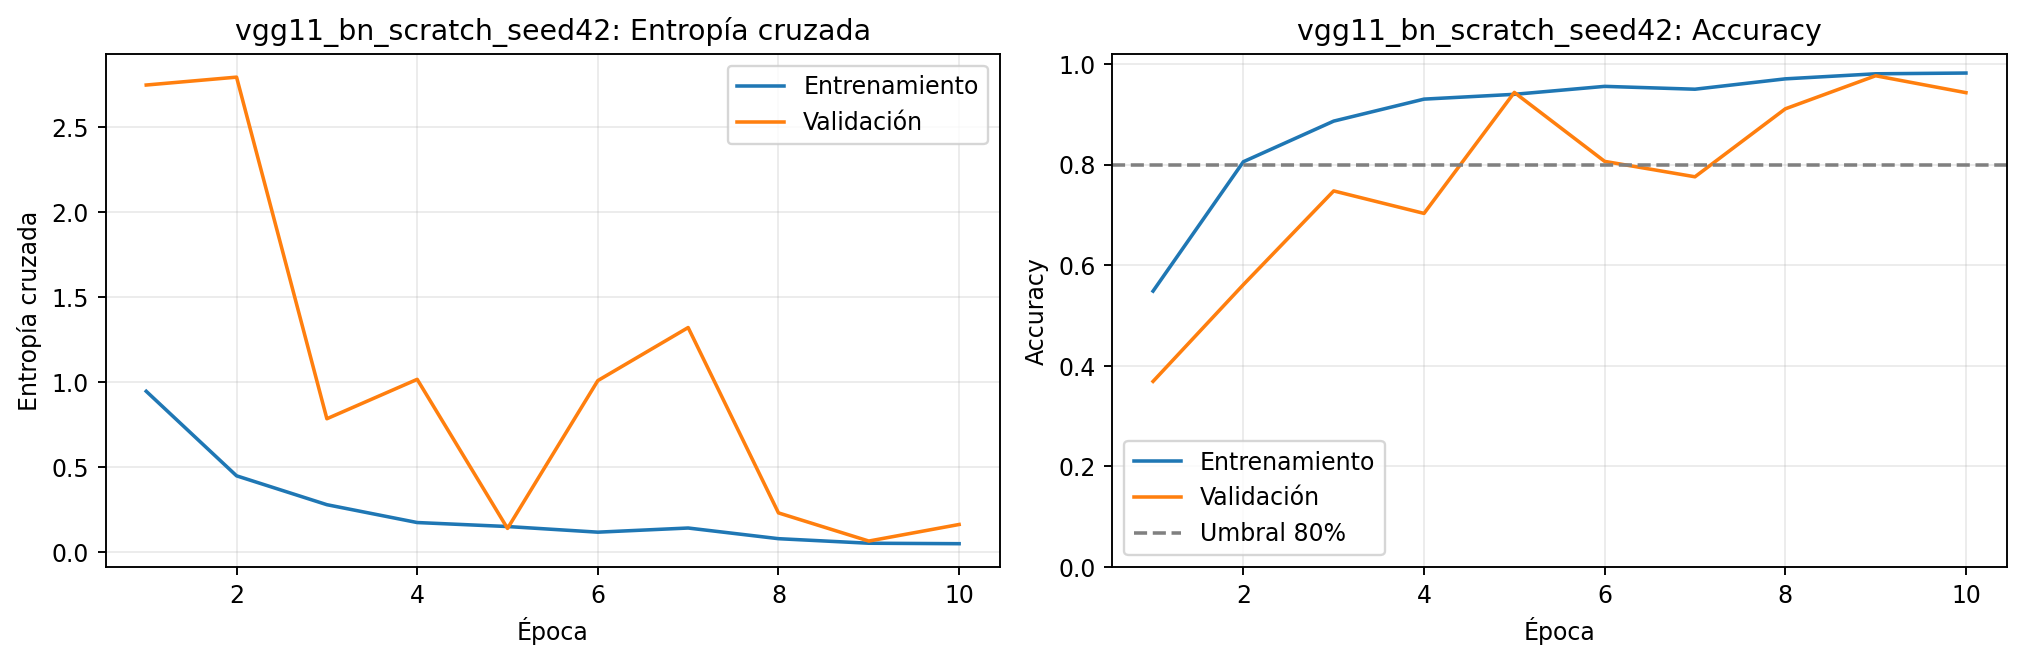

In [8]:
for modelo in ["lenet", "lenet_bn", "vgg11", "vgg11_bn"]:
    display(MostrarImagen(filename=f"results/figures/{modelo}_scratch_seed42_curves.png"))

## ¿BN ayuda a llegar antes al 80%?

Medimos la primera época que alcanza 80% de accuracy en validación.
Un valor vacío indica que no se llegó. El tiempo por época incluye el entrenamiento
y la lectura de datos, pero no la validación ni el guardado.

,name,best_val_accuracy,epoch_to_80_val,mean_train_seconds,status
0,lenet_scratch_seed42,0.668675,NaN,79.664632,completed
1,lenet_bn_scratch_seed42,0.587349,NaN,21.684756,completed
2,vgg11_scratch_seed42,0.251004,NaN,23.727318,completed
3,vgg11_bn_scratch_seed42,0.976406,5.0,23.831580,completed


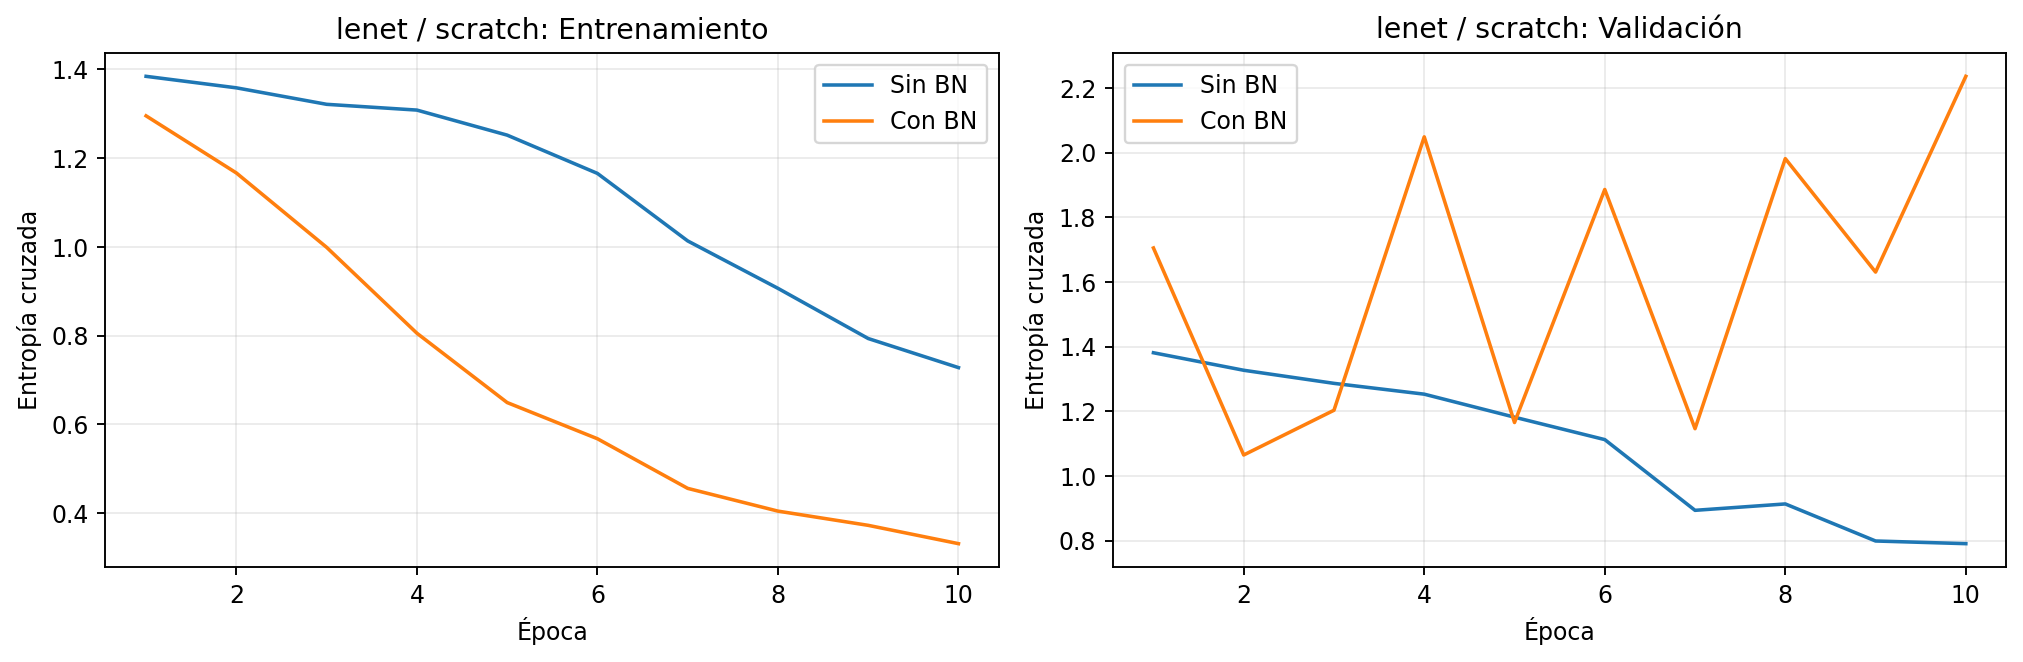

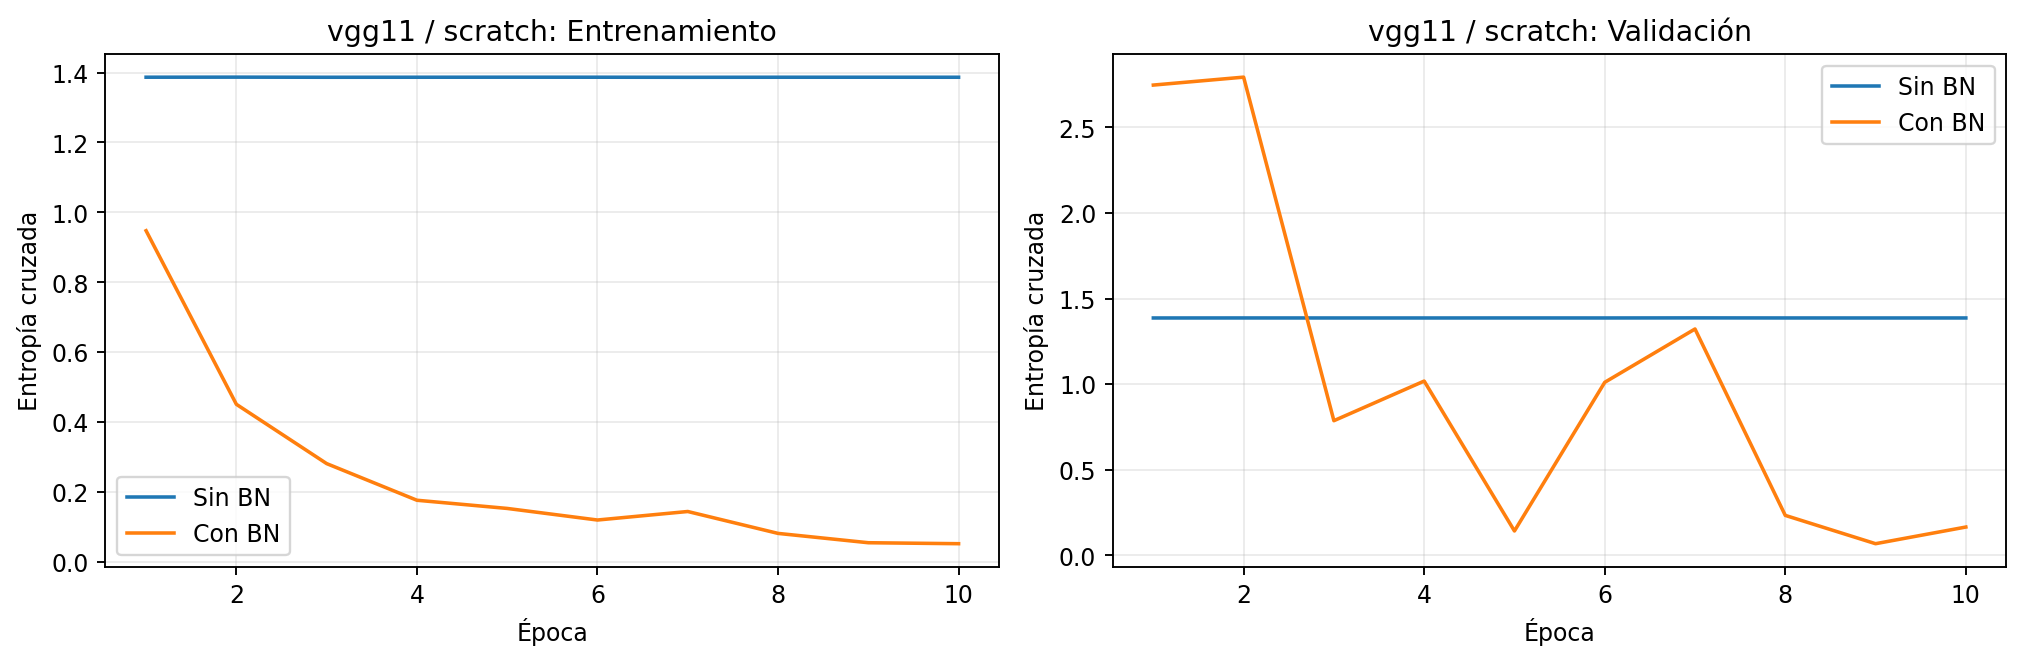

In [9]:
display(resultados[["name", "best_val_accuracy", "epoch_to_80_val", "mean_train_seconds", "status"]])
display(MostrarImagen(filename="results/figures/bn_lenet_scratch_seed42.png"))
display(MostrarImagen(filename="results/figures/bn_vgg11_scratch_seed42.png"))

## Probar una LR más alta

Repetimos solo LeNet y LeNet+BN con LR 0.1 durante 10 épocas. Los demás ajustes siguen iguales.
`unstable` indica que hubo valores NaN o infinitos. También hay que mirar las curvas:
una pérdida que oscila o crece puede indicar problemas aunque no aparezca ese estado.

In [10]:
resultados_lr_alta = run_suite(DEFAULT_SETTINGS, "high_lr", device="cuda")
comparacion = pd.concat([resultados, resultados_lr_alta], ignore_index=True)
display(comparacion[["architecture", "batch_norm", "lr", "best_val_accuracy", "epoch_to_80_val", "status", "failed_epoch"]])
comparacion.to_csv("results/tables/bn_lr_comparison.csv", index=False)
display(export_results("results"))

lenet_high_lr_seed42:   0%|          | 0/10 [00:00<?, ?it/s]

lenet_high_lr_seed42: completed; mejor val=0.26957831325301207; test=0.26135906714917573


lenet_bn_high_lr_seed42:   0%|          | 0/10 [00:00<?, ?it/s]

lenet_bn_high_lr_seed42: completed; mejor val=0.6646586345381527; test=0.4941696823482107


/tmp/ipykernel_560/3569448886.py:2: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  comparacion = pd.concat([resultados, resultados_lr_alta], ignore_index=True)


,architecture,batch_norm,lr,best_val_accuracy,epoch_to_80_val,status,failed_epoch
0,lenet,False,0.01,0.668675,NaN,completed,None
1,lenet,True,0.01,0.587349,NaN,completed,None
2,vgg11,False,0.01,0.251004,NaN,completed,None
3,vgg11,True,0.01,0.976406,5.0,completed,None
4,lenet,False,0.10,0.269578,NaN,completed,None
5,lenet,True,0.10,0.664659,NaN,completed,None


,name,parameters,trainable_parameters,mean_train_seconds,best_val_accuracy,test_accuracy,test_f1_macro,epoch_to_80_val,status
0,lenet_bn_high_lr_seed42,338020,338020,22.039844,0.664659,0.494170,0.491754,NaN,completed
1,lenet_bn_scratch_seed42,338020,338020,21.684756,0.587349,0.398874,0.403799,NaN,completed
2,lenet_high_lr_seed42,337976,337976,21.521964,0.269578,0.261359,0.134274,NaN,completed
3,lenet_scratch_seed42,337976,337976,79.664632,0.668675,0.467230,0.446554,NaN,completed
4,vgg11_bn_scratch_seed42,2966148,2966148,23.831580,0.976406,0.811419,0.821272,5.0,completed
5,vgg11_scratch_seed42,2963396,2963396,23.727318,0.251004,0.250905,0.100289,NaN,completed


Las curvas de LR alta se guardan en `results/figures/` como
`bn_lenet_high_lr_seed42.png`.
Un modelo que falla antes de terminar la primera época no tiene curva.

## Comentarios sobre BN

[Ioffe y Szegedy (2015)](https://proceedings.mlr.press/v37/ioffe15.html) propusieron
BN para reducir cambios en las entradas de las capas internas (*Internal Covariate Shift*)
y facilitar el entrenamiento con tasas mayores. BN normaliza por lote y aprende
una escala y un desplazamiento. Nuestras curvas muestran cómo entrenan los modelos,
pero no miden directamente ese cambio de distribución.

- ¿Qué modelo llegó antes al 80%? ¿Alguno no llegó?
- ¿BN mejoró la validación? ¿Cuánto cambió el tiempo por época?
- ¿Qué pasó con LR 0.1? ¿BN ayudó en LeNet?
- ¿Se separaron mucho los resultados de entrenamiento y validación?

**Respuesta:** VGG-11+BN fue el único modelo que alcanzó 80% de accuracy de validación: lo hizo en la época 5. LeNet, LeNet+BN y VGG-11 sin BN no llegaron a ese umbral en las 10 épocas.

BN no fue beneficiosa de la misma forma en las dos arquitecturas. En LeNet, el mejor accuracy de validación bajó de 66.87% a 58.73% al añadir BN (−8.13 puntos porcentuales). En VGG-11, en cambio, pasó de 25.10% a 97.64% (+72.54 pp), por lo que BN fue decisiva para que el modelo aprendiera. El tiempo medio por época cambió de 79.66 s a 21.68 s en LeNet y de 23.73 s a 23.83 s en VGG-11; la diferencia de tiempo de LeNet probablemente también depende de la variación del entorno de ejecución, así que conviene no atribuirla solo a BN.

Con LR = 0.1, LeNet sin BN obtuvo 26.96% de validación, frente a 66.87% con LR = 0.01; la tasa alta perjudicó claramente su aprendizaje. LeNet+BN llegó a 66.47% con LR = 0.1, ligeramente por encima de su resultado con LR = 0.01 (58.73%). Por tanto, en LeNet BN hizo el entrenamiento mucho más tolerante a la tasa alta, aunque no alcanzó 80%. Ninguna corrida de LR alta presentó NaN o infinitos.

En las curvas, LeNet+BN muestra una brecha mayor: el accuracy de entrenamiento sigue aumentando mientras el de validación oscila, señal de sobreajuste. VGG-11 sin BN permanece cerca del azar tanto en entrenamiento como en validación; no hay una brecha relevante porque no llegó a aprender. VGG-11+BN mantiene entrenamiento y validación altos y relativamente próximos, mientras que LeNet sin BN presenta una separación menor que su versión con BN. Una sola semilla no permite saber cuánto variarían estos resultados entre repeticiones.

Continúa con `03_transfer.ipynb`.